# Punjab Mandi Intelligence & Price Forecasting System

## 1. Business Problem

Agricultural commodity prices in Punjab mandis fluctuate frequently
due to changes in demand, supply, seasonality, and market conditions.

Farmers often face difficulty deciding when and where to sell their
crops because they lack reliable insights into historical and
expected market prices.

This project aims to analyze historical Punjab mandi price data,
identify price trends, compare market prices across districts,
and develop a Machine Learning model to forecast future
Modal Prices.

The goal is to help farmers and other stakeholders make
better-informed selling and market-related decisions.

In [85]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

# Data loading

In [86]:
df=pd.read_csv("../data/raw/bathinda_crops_mandi_data.csv")

In [87]:
# data information
print(f"Shape of data:- {df.shape}")
print(f"Columns:- {df.columns}")

Shape of data:- (45571, 11)
Columns:- Index(['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade',
       'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety'],
      dtype='object')


In [88]:
# first 5 rows
df.head()

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
0,08-07-2024,Banana,19,Bhatinda,Large,Bathinda,1450.0,1400.0,1450.0,Punjab,Other
1,09-07-2024,Banana,19,Bhatinda,Large,Bathinda,1450.0,1400.0,1400.0,Punjab,Other
2,11-07-2024,Banana,19,Bhatinda,Large,Bathinda,1450.0,1400.0,1400.0,Punjab,Other
3,12-07-2024,Banana,19,Bhatinda,Large,Bathinda,1450.0,1400.0,1400.0,Punjab,Other
4,16-07-2024,Banana,19,Bhatinda,Large,Bathinda,1500.0,1400.0,1400.0,Punjab,Other


In [89]:
# info about data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45571 entries, 0 to 45570
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Arrival_Date    45571 non-null  object 
 1   Commodity       45571 non-null  object 
 2   Commodity_Code  45571 non-null  int64  
 3   District        45571 non-null  object 
 4   Grade           45571 non-null  object 
 5   Market          45571 non-null  object 
 6   Max_Price       45571 non-null  float64
 7   Min_Price       45571 non-null  float64
 8   Modal_Price     45571 non-null  float64
 9   State           45571 non-null  object 
 10  Variety         45571 non-null  object 
dtypes: float64(3), int64(1), object(7)
memory usage: 3.8+ MB


In [90]:
# change datatypes of arrival data into datetime
df['Arrival_Date'] = pd.to_datetime(
    df['Arrival_Date'],
    format='%d-%m-%Y'
)

In [91]:
# drop the unwanted columns
df.drop(columns=["State","Commodity_Code","District"],axis=1,inplace=True)

# Data Cleaning

In [92]:
print("\n Check Null values:- ")
print(f"Null value:- {np.sum(df.isnull().sum())}")

# check duplication data
print("\n Duplicated Data:- ")
print(f"Duplicated_Date:- {df.duplicated().sum()}")


 Check Null values:- 
Null value:- 0

 Duplicated Data:- 
Duplicated_Date:- 0


* There is no any null and duplicate value present in the Data . Data is clean 

# Select only valid Price data

In [93]:
df=df[
(df['Max_Price']>=0) & (df["Min_Price"]>=0) & (df["Modal_Price"]>=0)
]

In [94]:
# summary statistics of data
df.describe()

,Arrival_Date,Max_Price,Min_Price,Modal_Price
count,45571,45571.000000,45571.000000,45571.000000
mean,2025-05-20 05:42:14.954247168,3424.169623,2627.372011,2972.108359
min,2023-11-08 00:00:00,0.000000,0.000000,20.000000
25%,2024-08-03 00:00:00,1500.000000,1000.000000,1300.000000
50%,2025-05-15 00:00:00,2500.000000,2000.000000,2200.000000
75%,2026-03-13 00:00:00,3500.000000,3100.000000,3400.000000
max,2026-11-07 00:00:00,36000.000000,29000.000000,30000.000000
std,NaN,3626.736524,2381.381348,2809.890121


In [95]:
# cat_cols summary statistics
df.describe(include="object")

,Commodity,Grade,Market,Variety
count,45571,45571,45571,45571
unique,63,10,26,67
top,Potato,FAQ,Rampuraphul(Nabha Mandi) APMC,Other
freq,5215,21447,6669,36138


In [96]:
# work only selected crops
top_crops = [
    'Potato',
    'Onion',
    'Tomato',
    'Banana',
    'Apple'
]

df = df[df['Commodity'].isin(top_crops)].copy()

# Feature Engineering

In [97]:
# Extract date features
df['Year'] = df['Arrival_Date'].dt.year
df['Month'] = df['Arrival_Date'].dt.month
df['Day'] = df['Arrival_Date'].dt.day
df['Day_of_week'] = df['Arrival_Date'].dt.dayofweek

# make a season feaure
def get_season(month):

    if month in [3,4,5,6]:
        return "Summer"
    elif month in [7,8,9]:
        return "Mansoon"
    elif month in [10,11]:
        return "Autumn"
    else:
        return "Winter"

df["Season"]=df["Month"].apply(get_season)

# Numerical Data Analysis



 Max_Price Analysis
25% :- 1500.0
Median:- 2350.0
Mean:- 3378.509160234353
std:- 3723.152820967935
Max:- 32000.0
Skew:- 3.081616179691888


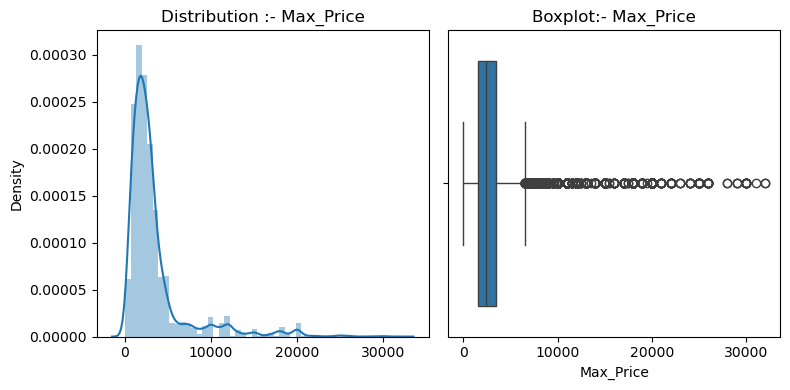


 Min_Price Analysis
25% :- 1200.0
Median:- 2000.0
Mean:- 2555.825862549986
std:- 2075.197434719138
Max:- 22000.0
Skew:- 1.9616521389291801


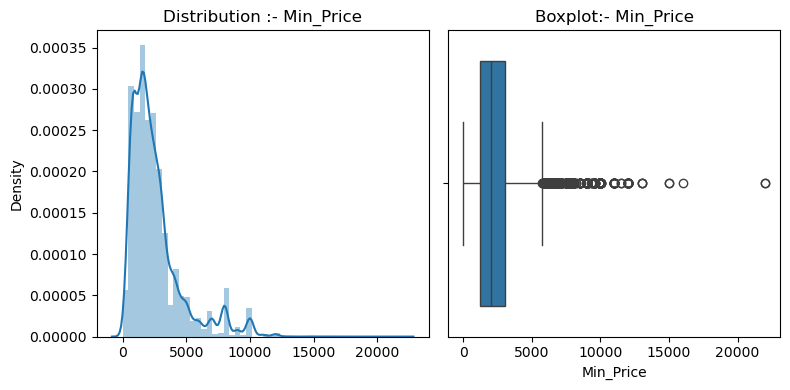


 Modal_Price Analysis
25% :- 1396.25
Median:- 2100.0
Mean:- 2914.249632660653
std:- 2720.2041474931325
Max:- 24000.0
Skew:- 2.5003757808801383


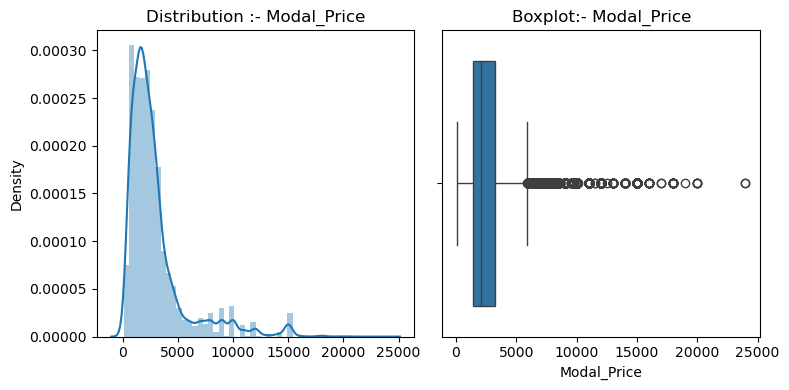

In [98]:
# extract num_cols 
num_cols=df.select_dtypes(include=[np.number])

for col in num_cols.drop(columns=["Year","Month","Day","Day_of_week"],axis=1):
    print(f"\n {col} Analysis")

    q1=df[col].quantile(0.25)
    median=df[col].median()
    mean=df[col].mean()
    std=df[col].std()
    max=df[col].max()
    skew=df[col].skew()

    print(f"25% :- {q1}")
    print(f"Median:- {median}")
    print(f"Mean:- {mean}")
    print(f"std:- {std}")
    print(f"Max:- {max}")
    print(f"Skew:- {skew}")

    # visualization
    plt.figure(figsize=(8,4))

    plt.subplot(121)
    sns.distplot(x=df[col],hist=True)
    plt.title(f"Distribution :- {col}")
    
    # boxplot
    plt.subplot(122)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot:- {col}")
    

    plt.tight_layout()
    plt.show()

* All three price columns are positively skewed, indicating that most observations are concentrated at relatively lower prices, with a few extremely high prices pulling the distribution towards the right.

# Categorical Data Analysis


 Commodity Distribution 
Commodity
Potato    5215
Onion     5191
Tomato    4450
Banana    3867
Apple     2783
Name: count, dtype: int64


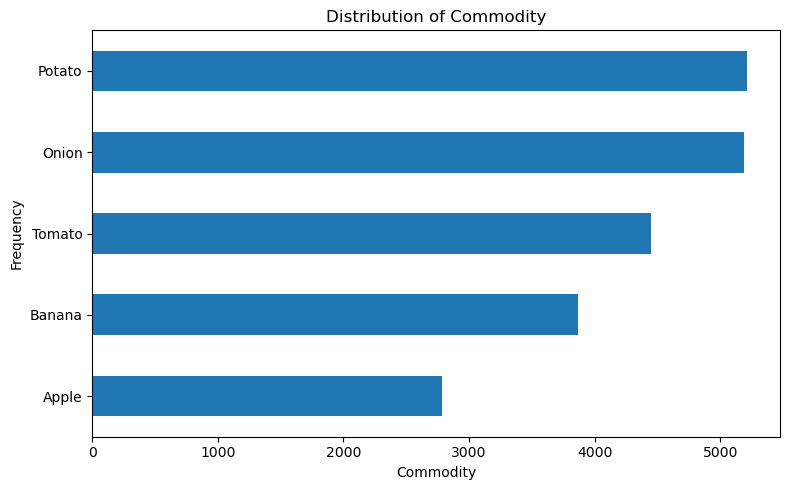


 Grade Distribution 
Grade
FAQ        9200
Medium     5083
Grade A    2648
Grade B    1571
Large      1096
Non-FAQ     818
Local       783
Small       307
Name: count, dtype: int64


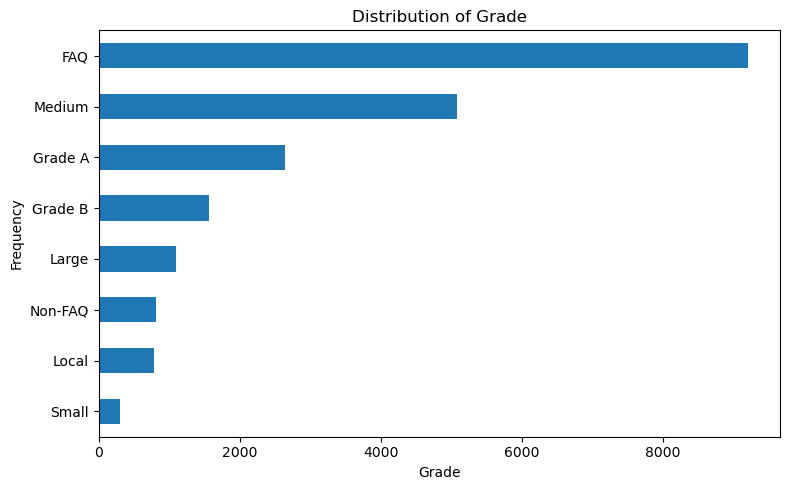


 Market Distribution 
Market
Bhagta Bhai Ka                   2892
Raman                            2740
Bathinda                         2621
Talwandi Sabo                    2202
Rampuraphul(Nabha Mandi)         2088
Rampuraphul(Nabha Mandi) APMC    1662
Raman APMC                       1379
Maur                             1319
Bathinda APMC                    1170
Bhagta Bhai Ka APMC              1136
Talwandi Sabo APMC               1038
Maur APMC                         495
Bhucho                            460
Bhucho APMC                       300
Rampura Phul                        4
Name: count, dtype: int64


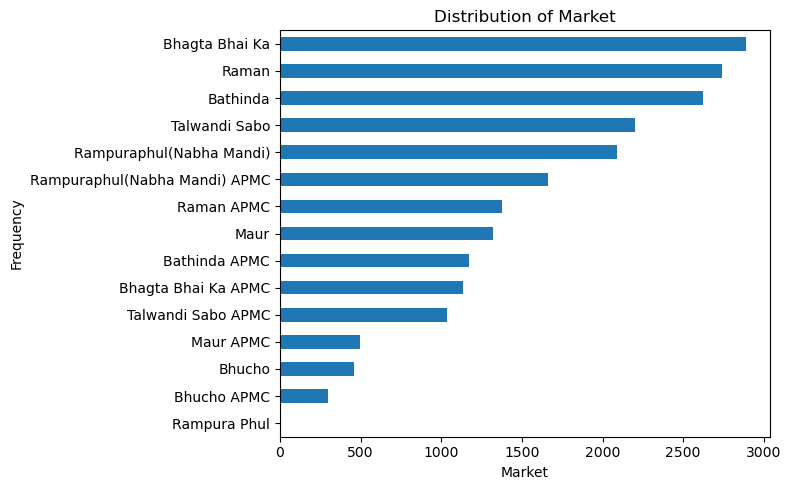


 Variety Distribution 
Variety
Other                 19932
Apple                   536
Kasmir/Shimla - II      227
Banana - Ripe           214
Medium                  115
Onion                   101
American                100
Potato                   86
Local                    80
Bellary                  77
Red Nanital              28
Kufri Giriraj             6
Hybrid                    2
(Red Nanital)             2
Name: count, dtype: int64


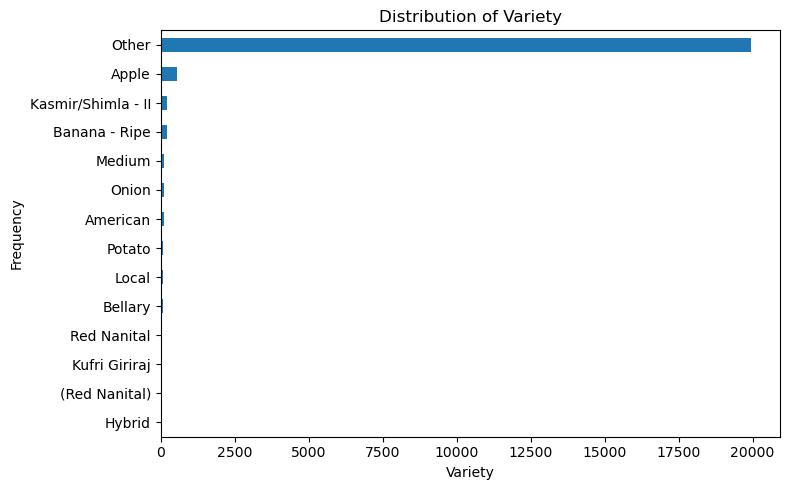


 Season Distribution 
Season
Summer     6517
Mansoon    5682
Winter     5298
Autumn     4009
Name: count, dtype: int64


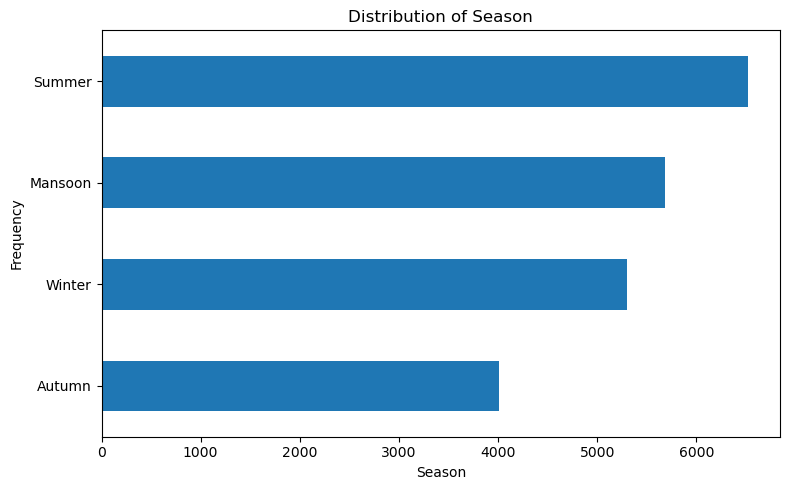

In [99]:
cat_cols=df.select_dtypes(include=["object"])

for col in cat_cols:
    print(f"\n {col} Distribution ")

    print(df[col].value_counts())

    # visualization
    plt.figure(figsize=(8,5))
    df[col].value_counts().sort_values(ascending=True).plot(kind="barh")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

* The categorical features show varying levels of imbalance. Commodity and season are relatively balanced, whereas Grade, Market, and especially Variety have uneven distributions. These differences should be considered during data preprocessing and model development

# Stationarity Checking

In [100]:
pd.crosstab(stationarity_df["Status"],stationarity_df["Commodity"])

Commodity,Apple,Banana,Onion,Potato,Tomato
Status,,,,,
Already Stationary,6,8,7,9,6
Fixed,5,3,7,5,5
Non-Stationary,0,0,0,0,1


# Time series Analysis

In [101]:
# sort the time
df=df.sort_values("Arrival_Date")

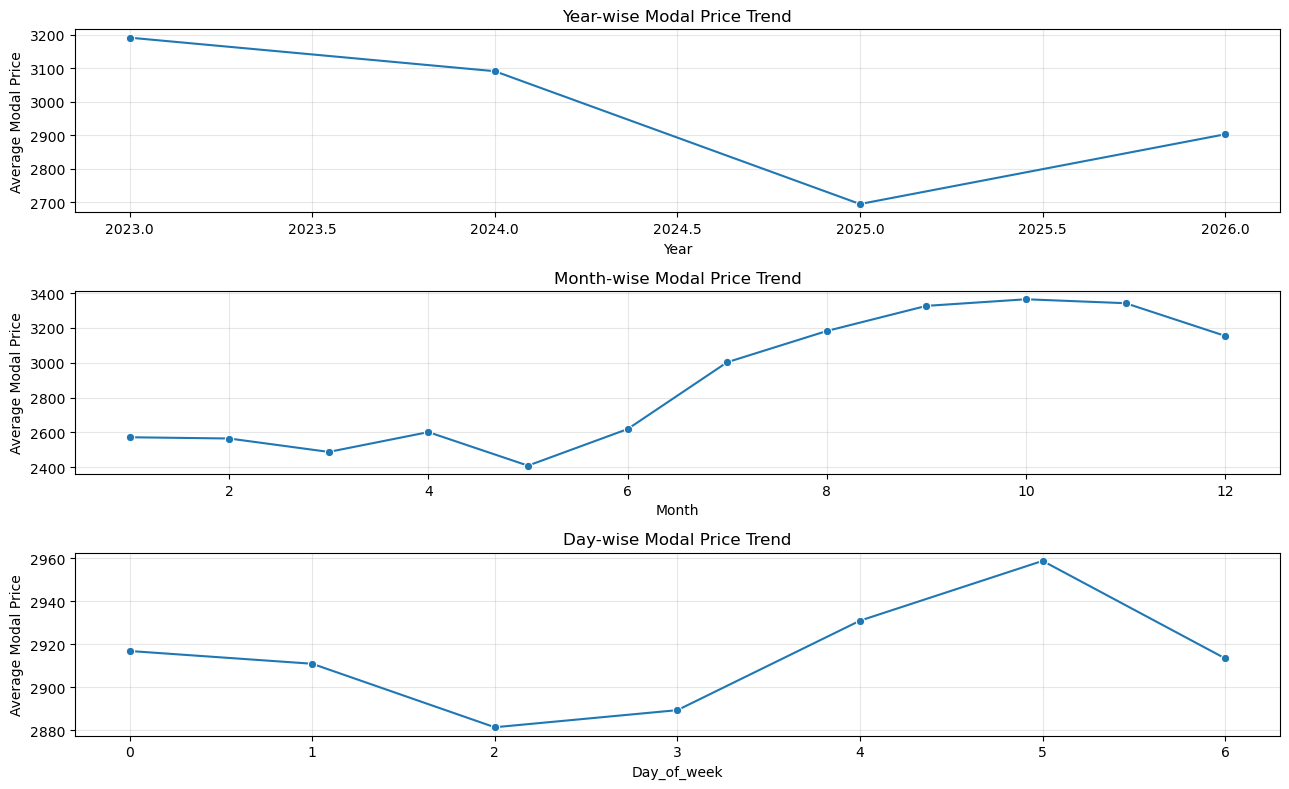

In [102]:

fig, axes = plt.subplots(3, 1, figsize=(13, 8))

# Year-wise
year_data = df.groupby('Year')['Modal_Price'].mean().reset_index()
sns.lineplot(data=year_data, x='Year', y='Modal_Price',
             marker='o', ax=axes[0])
axes[0].set_title('Year-wise Modal Price Trend')

# Month-wise
month_data = df.groupby('Month')['Modal_Price'].mean().reset_index()
sns.lineplot(data=month_data, x='Month', y='Modal_Price',
             marker='o', ax=axes[1])
axes[1].set_title('Month-wise Modal Price Trend')

# Day-wise
day_data = df.groupby('Day_of_week')['Modal_Price'].mean().reset_index()
sns.lineplot(data=day_data, x='Day_of_week', y='Modal_Price',
             marker='o', ax=axes[2])
axes[2].set_title('Day-wise Modal Price Trend')

for ax in axes:
    ax.set_ylabel('Average Modal Price')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


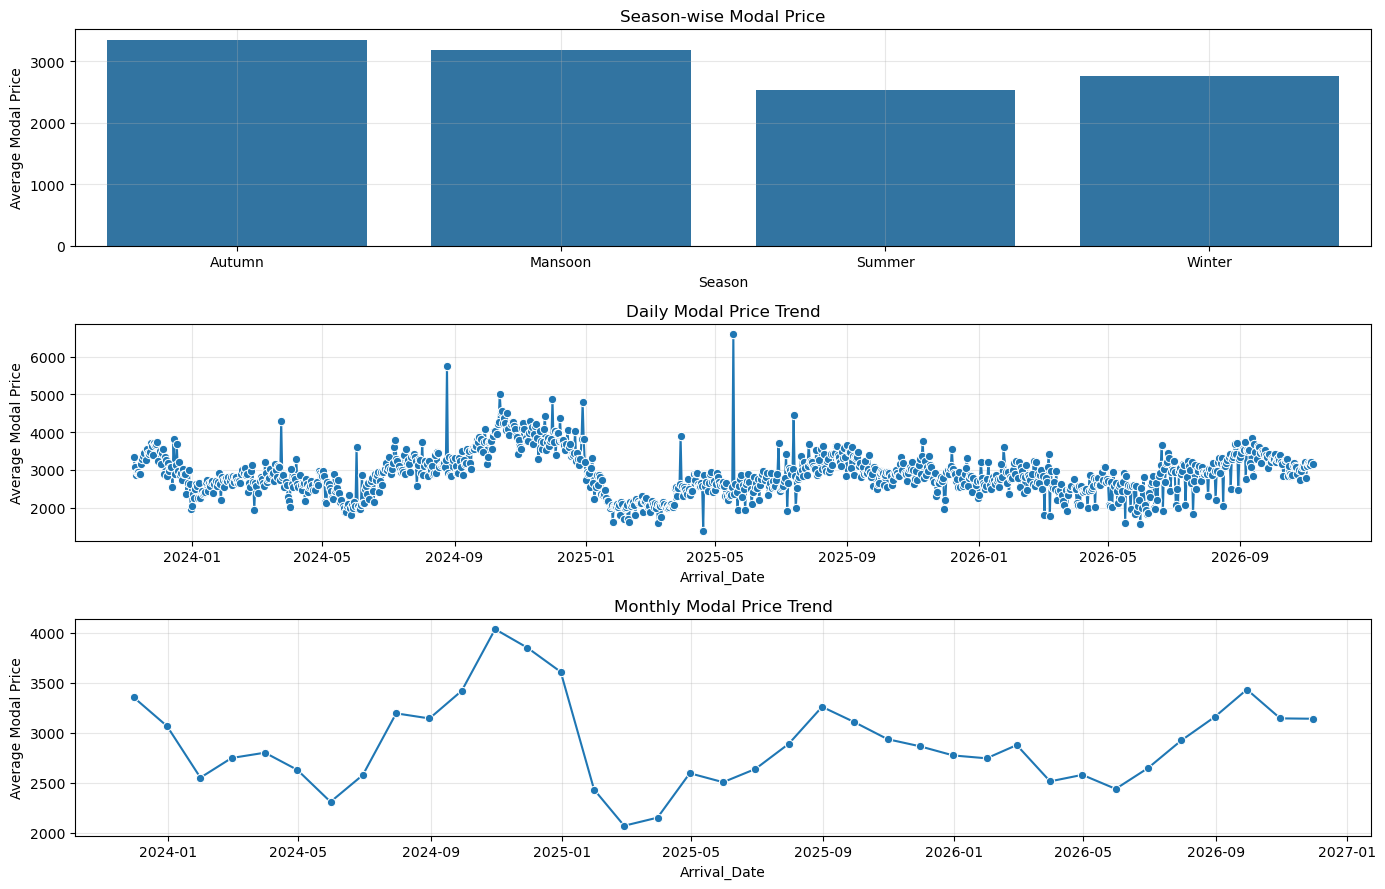

In [103]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

# Season-wise
season_data = df.groupby('Season')['Modal_Price'].mean().reset_index()
sns.barplot(data=season_data, x='Season', y='Modal_Price', ax=axes[0])
axes[0].set_title('Season-wise Modal Price')

# Daily Trend
daily_data = df.groupby('Arrival_Date')['Modal_Price'].mean().reset_index()
sns.lineplot(data=daily_data, x='Arrival_Date', y='Modal_Price',
             marker='o', ax=axes[1])
axes[1].set_title('Daily Modal Price Trend')

# Monthly Trend
monthly_data = (
    df.set_index('Arrival_Date')['Modal_Price']
    .resample('ME').mean()
    .reset_index()
)

sns.lineplot(data=monthly_data, x='Arrival_Date', y='Modal_Price',
             marker='o', ax=axes[2])
axes[2].set_title('Monthly Modal Price Trend')

for ax in axes:
    ax.set_ylabel('Average Modal Price')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Check which commodity has high Avg modal Price

  Commodity  Modal_Price
0     Apple  8616.561983
1     Onion  2505.597436
2    Banana  2449.892570
3    Tomato  2444.923804
4    Potato  1022.772543


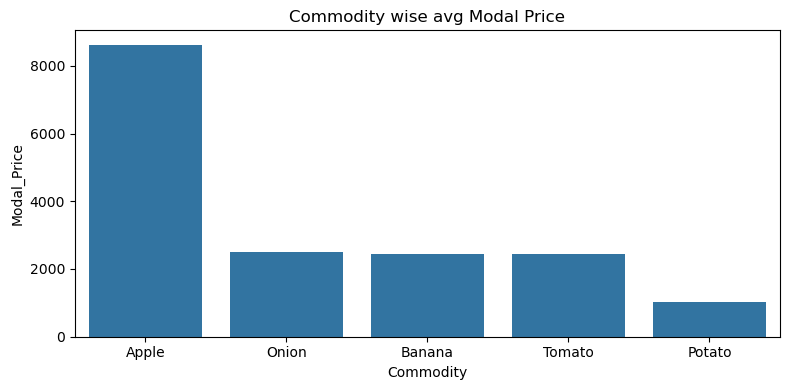

In [104]:
commodity_price=df.groupby("Commodity")["Modal_Price"].mean().sort_values(ascending=False).reset_index()
print(commodity_price)

# visualization
plt.figure(figsize=(8,4))
sns.barplot(
    x="Commodity",
    y="Modal_Price",
    data=commodity_price
)
plt.title("Commodity wise avg Modal Price")
plt.tight_layout()
plt.show()

**Insight – Commodity vs Modal Price**

- Apple has the highest average modal price among all commodities.
- Onion, Banana, and Tomato have relatively similar average modal prices.
- Potato has the lowest average modal price compared to other commodities.
- Based on these observations, Apple may offer better revenue potential. However, investment decisions should also consider demand, production costs, market trends, and profit margins.

# Grade Analysis and Check Market Report of Bathinda 

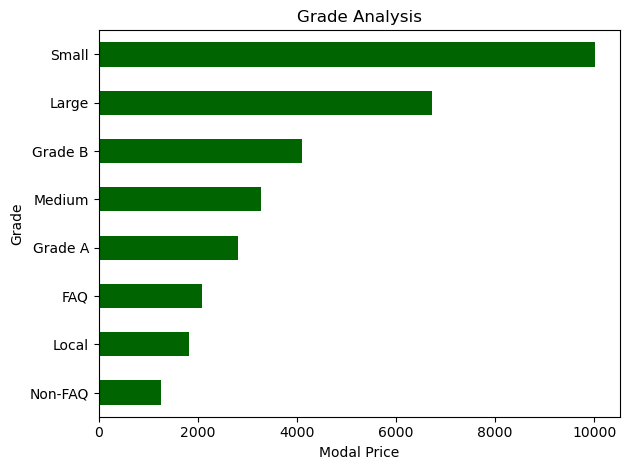

In [105]:
grade_price=df.groupby("Grade")["Modal_Price"].mean().sort_values(ascending=True).plot(kind='barh',color="darkgreen")
plt.title("Grade Analysis")
plt.xlabel("Modal Price")
plt.ylabel("Grade")

plt.tight_layout()
plt.show()


**Insight – Grade vs Average Modal Price**

- Small grade commodities have the highest average modal price (₹10,020), followed by Large grade commodities (₹6,721).
- Grade B and Medium categories show moderate average modal prices.
- Non-FAQ commodities have the lowest average modal price (₹1,250).
- The results indicate considerable variation in average modal prices across different grades.

**Conclusion:** Grade appears to be an important factor associated with commodity prices. However, these differences should be interpreted carefully, as commodity type, market location, and sample size may also influence the average prices.

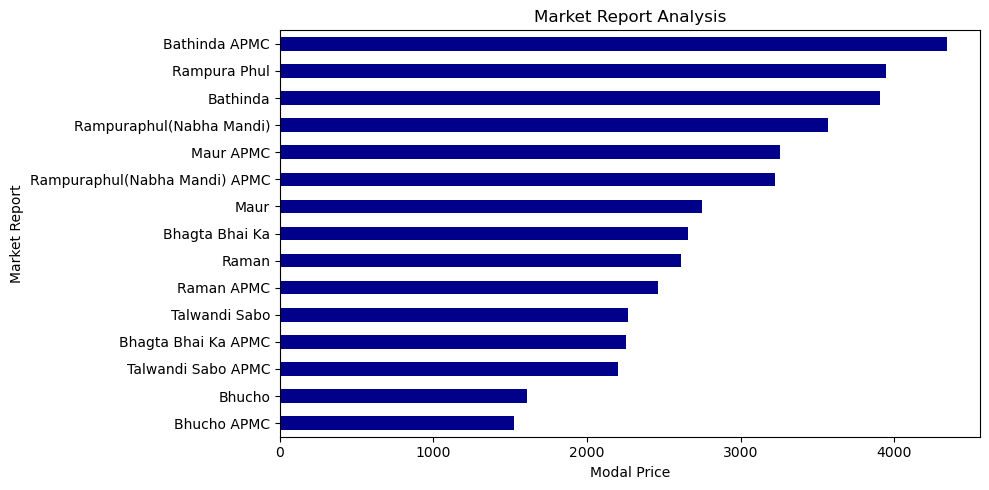

In [106]:
# Market Report Analysis
plt.figure(figsize=(10,5))
df.groupby("Market")["Modal_Price"].mean().sort_values(ascending=True).plot(kind='barh',color='darkblue')
plt.title("Market Report Analysis")
plt.xlabel("Modal Price")
plt.ylabel("Market Report")

plt.tight_layout()
plt.show()

# correlation Analysis

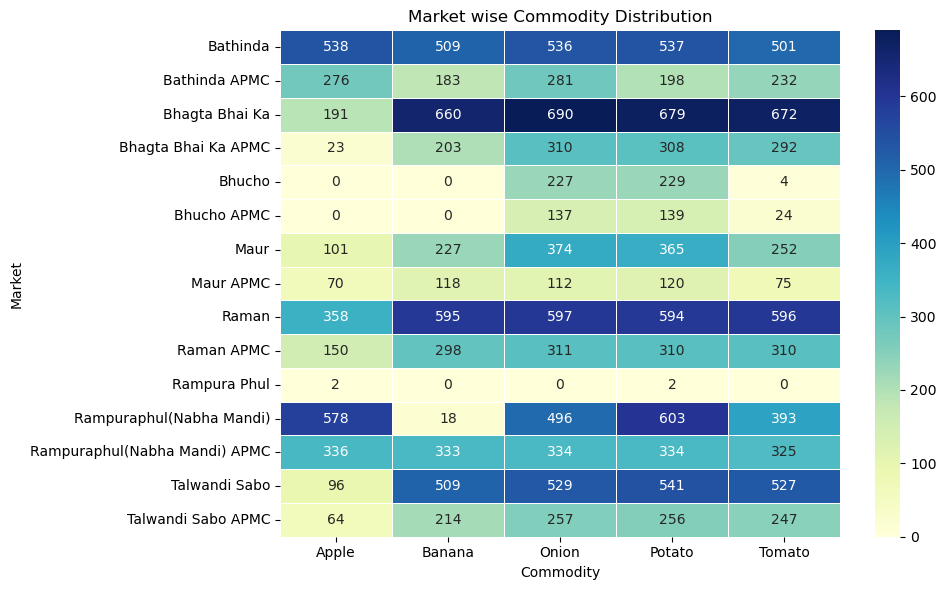

In [107]:
# Market vs commodity
ct=pd.crosstab(df["Market"],df["Commodity"])

plt.figure(figsize=(10,6))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu',
            linewidths=0.5)
plt.title("Market wise Commodity Distribution")
plt.tight_layout()
plt.show()

**Insight – Market-wise Commodity Distribution**

- Bathinda shows a nearly balanced distribution of all five commodities, with approximately 500 records for each.
- Bhagta Bhai Ka and Raman have a higher representation of Banana, Onion, Potato, and Tomato compared to Apple.
- Talwandi Sabo also shows a relatively higher number of records for Banana, Onion, Potato, and Tomato, while Apple has fewer observations.
- Rampuraphul (Nabha Mandi) has a higher representation of Apple and Potato, whereas Banana has very few records.
- Bhucho has records mainly for Onion and Potato, with almost no representation of Apple and Banana.
- Rampura Phul has only four observations, making it insufficient for meaningful comparisons.

**Conclusion:** The distribution of commodities varies across markets, indicating differences in the representation of commodities in the dataset. These patterns may reflect market-specific availability or data collection differences.

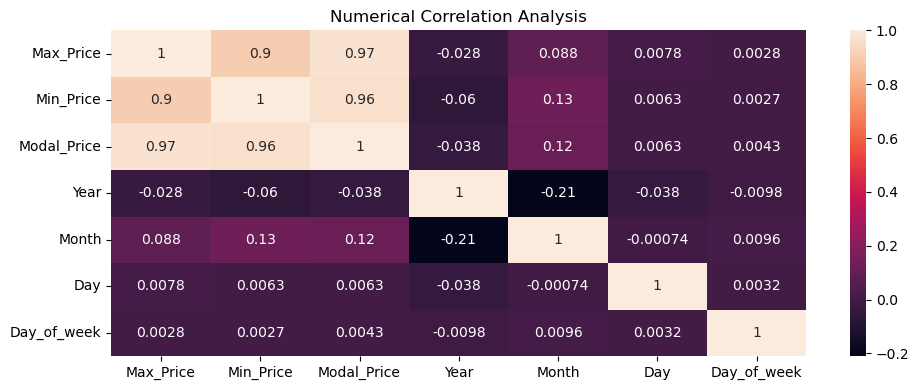

In [108]:
# Numerical Correlation
corr=df.select_dtypes(include=[np.number]).corr()

# visualization
plt.figure(figsize=(10,4))
sns.heatmap(
    corr,
    annot=True
)
plt.title("Numerical Correlation Analysis")
plt.tight_layout()
plt.show()

**Insight – Numerical Features Correlation Analysis**

- A very strong positive correlation is observed among all three price variables: Max_Price, Min_Price, and Modal_Price.
- Max_Price has the strongest correlation with Modal_Price (0.969), followed by Min_Price (0.965).
- Year shows a negligible negative correlation with the price variables, indicating almost no linear association.
- Month exhibits a weak positive correlation with price variables, suggesting slight monthly variation.
- Day and Day_of_week have negligible correlations with all price variables.

**Conclusion:** The three price variables are strongly associated with each other, whereas the date-derived features show weak linear relationships with prices. Further time-based analysis may help identify seasonal patterns that simple correlation cannot capture.

In [109]:
# Save the cleaned data
df.to_csv("../data/proceed/clean_data.csv", index=False)